<a href="https://colab.research.google.com/github/team2601/arabic-handwriting-cnn/blob/main/Notebooks/1_PreProcessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Setup

In [ ]:
import os
import json
import glob
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split

# Set seeds FIRST so every step in this notebook is reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

from google.colab import drive
drive.mount("/content/drive")

# Input (raw cleaned AHAWP dataset) and Output (clean shared preprocessed splits)
RAW_DIR = "/content/drive/MyDrive/DL_Project/data/ahawp_alphabets_clean"
OUT_DIR = "/content/drive/MyDrive/DL_Project/data/ahawp_18classes_32x32"
os.makedirs(OUT_DIR, exist_ok=True)

assert os.path.exists(RAW_DIR), f"Raw dataset folder not found: {RAW_DIR}"
print("Raw folder:", RAW_DIR)
print("Output folder:", OUT_DIR)

Mounted at /content/drive
Raw folder: /content/drive/MyDrive/DL_Project/data/ahawp_alphabets_clean
Output folder: /content/drive/MyDrive/DL_Project/data/ahawp_18classes_32x32


## 2.  Mapping (64 Forms → 18 Classes)




In [ ]:
POSITION_SUFFIXES = ("_begin", "_middle", "_end", "_regular")

SPECIAL_MERGE_MAP = {
    "alif_hamza": "alif",
}

def folder_to_letter(folder_name):
    """Map a positional folder name (e.g. 'feh_middle', 'alif_hamza') to its base letter."""
    if folder_name in SPECIAL_MERGE_MAP:
        return SPECIAL_MERGE_MAP[folder_name]
    for suffix in POSITION_SUFFIXES:
        if folder_name.endswith(suffix):
            return folder_name[: -len(suffix)]
    return folder_name

subfolders = sorted(
    d for d in os.listdir(RAW_DIR)
    if os.path.isdir(os.path.join(RAW_DIR, d))
)

# Verify mapping before loading images
mapping_rows = [
    {"folder": f, "merged_letter": folder_to_letter(f)}
    for f in subfolders
]
mapping_df = pd.DataFrame(mapping_rows)
merged_classes = sorted(mapping_df["merged_letter"].unique())

print(f"Subfolders found:     {len(subfolders)}")
print(f"Merged letter classes:{len(merged_classes)}")
print("Classes:", merged_classes)

assert len(merged_classes) == 18, f"Expected 18 classes, got {len(merged_classes)}"
label_to_id = {name: idx for idx, name in enumerate(merged_classes)}
id_to_label = {idx: name for name, idx in label_to_id.items()}

Subfolders found:     64
Merged letter classes:18
Classes: ['ain', 'alif', 'beh', 'dal', 'feh', 'heh', 'jeem', 'kaf', 'lam', 'meem', 'noon', 'qaf', 'raa', 'sad', 'seen', 'tah', 'waw', 'yaa']


## 3.  Resize (`32 × 32`)



In [ ]:
IMG_SIZE = 32

def preprocess_image(gray_img, target_size=32, ink_thresh=240, pad_margin=8):
    """Crop excess white border, pad to square with white, and resize to target_size x target_size."""
    # 1. Find bounding box of dark ink pixels (< ink_thresh)
    coords = np.column_stack(np.where(gray_img < ink_thresh))
    if len(coords) > 0:
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0) + 1
        y_min = max(0, y_min - pad_margin)
        x_min = max(0, x_min - pad_margin)
        y_max = min(gray_img.shape[0], y_max + pad_margin)
        x_max = min(gray_img.shape[1], x_max + pad_margin)
        cropped = gray_img[y_min:y_max, x_min:x_max]
    else:
        cropped = gray_img

    # 2. Pad to square with white background (255)
    h, w = cropped.shape
    side = max(h, w)
    top = (side - h) // 2
    bottom = side - h - top
    left = (side - w) // 2
    right = side - w - left

    square = cv2.copyMakeBorder(
        cropped, top, bottom, left, right,
        borderType=cv2.BORDER_CONSTANT,
        value=255,
    )

    # 3. Downscale cleanly with INTER_AREA
    resized = cv2.resize(square, (target_size, target_size), interpolation=cv2.INTER_AREA)
    return resized

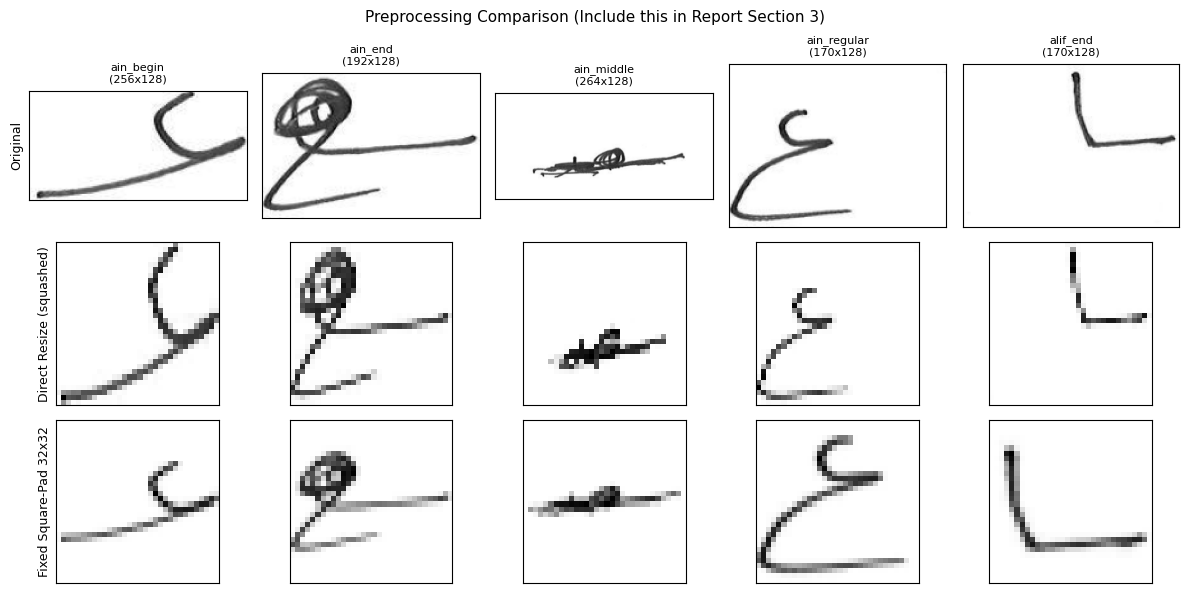

In [ ]:
# Visual sanity check: compare Original vs. Direct Resize vs. Fixed Square-Pad Resize
sample_paths = []
for folder in subfolders[:5]:
    imgs = sorted(glob.glob(os.path.join(RAW_DIR, folder, "*.png")))
    if imgs:
        sample_paths.append((folder, imgs[0]))

fig, axes = plt.subplots(3, len(sample_paths), figsize=(12, 6))
row_titles = ["Original", "Direct Resize (squashed)", "Fixed Square-Pad 32x32"]

for col, (folder, path) in enumerate(sample_paths):
    raw = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    direct = cv2.resize(raw, (IMG_SIZE, IMG_SIZE))
    fixed = preprocess_image(raw, IMG_SIZE)

    for row, img_show in enumerate([raw, direct, fixed]):
        ax = axes[row, col]
        ax.imshow(img_show, cmap="gray")
        if row == 0:
            ax.set_title(f"{folder}\n({raw.shape[1]}x{raw.shape[0]})", fontsize=8)
        if col == 0:
            ax.set_ylabel(row_titles[row], fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])

plt.suptitle("Preprocessing Comparison (Include this in Report Section 3)", fontsize=11)
plt.tight_layout()
plt.show()

## 4. Load & Preprocess



In [ ]:
EXTENSIONS = ("*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tiff")

# Gather all (image_path, class_id) pairs cleanly
items = []
for folder in subfolders:
    letter = folder_to_letter(folder)
    class_id = label_to_id[letter]
    folder_path = os.path.join(RAW_DIR, folder)
    for ext in EXTENSIONS:
        for img_path in sorted(glob.glob(os.path.join(folder_path, ext))):
            items.append((img_path, class_id))

print(f"Total image files discovered: {len(items)}")

# Pre-allocate arrays for speed and low memory usage
X_list = []
y_list = []
failed_files = []

for img_path, class_id in tqdm(items, desc="Preprocessing AHAWP"):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        failed_files.append(img_path)
        continue
    processed = preprocess_image(img, IMG_SIZE)
    X_list.append(processed)
    y_list.append(class_id)

# Convert to float32 in [0, 1] and add channel dimension -> (N, 32, 32, 1)
X = (np.array(X_list, dtype=np.float32) / 255.0)[..., np.newaxis]
y = np.array(y_list, dtype=np.int32)

print(f"\nLoaded successfully: {len(X)} images | Failed/skipped: {len(failed_files)}")
print(f"X shape: {X.shape} | dtype: {X.dtype} | range: [{X.min():.2f}, {X.max():.2f}]")
print(f"y shape: {y.shape} | dtype: {y.dtype} | unique classes: {len(np.unique(y))}")

Total image files discovered: 52379


Preprocessing AHAWP:   0%|          | 0/52379 [00:00<?, ?it/s]


Loaded successfully: 52379 images | Failed/skipped: 0
X shape: (52379, 32, 32, 1) | dtype: float32 | range: [0.09, 1.00]
y shape: (52379,) | dtype: int32 | unique classes: 18


## 5. Data Split  (60% / 20% / 20%)


In [ ]:
# Step 1: 60% train, 40% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    stratify=y,
    random_state=SEED,
)

# Step 2: split 40% temp evenly -> 20% validation, 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED,
)

print(f"Train set: {X_train.shape} | {len(y_train):5d} ({len(y_train)/len(y):.1%})")
print(f"Val set:   {X_val.shape} | {len(y_val):5d} ({len(y_val)/len(y):.1%})")
print(f"Test set:  {X_test.shape} | {len(y_test):5d} ({len(y_test)/len(y):.1%})")

# Verify every class has proportional counts across all 3 splits
split_df = pd.DataFrame({
    "class_id": range(len(merged_classes)),
    "letter": merged_classes,
    "train": [int((y_train == i).sum()) for i in range(len(merged_classes))],
    "val":   [int((y_val == i).sum()) for i in range(len(merged_classes))],
    "test":  [int((y_test == i).sum()) for i in range(len(merged_classes))],
})
split_df["total"] = split_df["train"] + split_df["val"] + split_df["test"]
display(split_df)

Train set: (31427, 32, 32, 1) | 31427 (60.0%)
Val set:   (10476, 32, 32, 1) | 10476 (20.0%)
Test set:  (10476, 32, 32, 1) | 10476 (20.0%)


,class_id,letter,train,val,test,total
0,0,ain,1968,656,656,3280
1,1,alif,1476,492,492,2460
2,2,beh,1968,656,656,3280
3,3,dal,984,328,328,1640
4,4,feh,1950,650,650,3250
5,5,heh,1956,652,652,3260
6,6,jeem,1968,656,656,3280
7,7,kaf,1968,656,656,3280
8,8,lam,1968,656,656,3280
9,9,meem,1968,656,656,3280


## 6. Save Preprocessed Splits


In [ ]:
np.save(os.path.join(OUT_DIR, "X_train.npy"), X_train)
np.save(os.path.join(OUT_DIR, "y_train.npy"), y_train)
np.save(os.path.join(OUT_DIR, "X_val.npy"),   X_val)
np.save(os.path.join(OUT_DIR, "y_val.npy"),   y_val)
np.save(os.path.join(OUT_DIR, "X_test.npy"),  X_test)
np.save(os.path.join(OUT_DIR, "y_test.npy"),  y_test)

# Save label mapping so every model (Paper CNN & Baseline) uses identical class indices
label_map = {
    "num_classes": len(merged_classes),
    "classes": merged_classes,
    "label_to_id": label_to_id,
    "id_to_label": {str(k): v for k, v in id_to_label.items()},
}
with open(os.path.join(OUT_DIR, "label_map.json"), "w", encoding="utf-8") as f:
    json.dump(label_map, f, indent=2)

# Save split summary CSV for Report Section 2
split_df.to_csv(os.path.join(OUT_DIR, "split_summary.csv"), index=False)

print("Saved all clean splits and metadata to:", OUT_DIR)
for fname in sorted(os.listdir(OUT_DIR)):
    size_mb = os.path.getsize(os.path.join(OUT_DIR, fname)) / (1024 * 1024)
    print(f"  - {fname:20s} ({size_mb:.2f} MB)")

Saved all clean splits and metadata to: /content/drive/MyDrive/DL_Project/data/ahawp_18classes_32x32
  - X_test.npy           (40.92 MB)
  - X_train.npy          (122.76 MB)
  - X_val.npy            (40.92 MB)
  - label_map.json       (0.00 MB)
  - split_summary.csv    (0.00 MB)
  - y_test.npy           (0.04 MB)
  - y_train.npy          (0.12 MB)
  - y_val.npy            (0.04 MB)


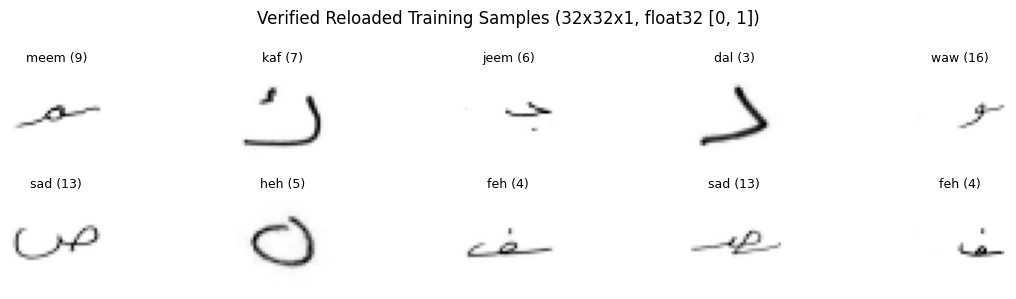

All verification checks passed!


In [ ]:
# Reload from Drive and display 10 random training samples to verify integrity
X_tr_check = np.load(os.path.join(OUT_DIR, "X_train.npy"))
y_tr_check = np.load(os.path.join(OUT_DIR, "y_train.npy"))
with open(os.path.join(OUT_DIR, "label_map.json"), "r", encoding="utf-8") as f:
    lm = json.load(f)

assert X_tr_check.shape == (len(y_tr_check), 32, 32, 1)
assert X_tr_check.dtype == np.float32
assert 0.0 <= X_tr_check.min() and X_tr_check.max() <= 1.0
assert lm["num_classes"] == 18

rng = np.random.default_rng(SEED)
idxs = rng.choice(len(X_tr_check), size=10, replace=False)

plt.figure(figsize=(12, 3))
for i, idx in enumerate(idxs):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_tr_check[idx].squeeze(), cmap="gray")
    plt.title(f"{lm['classes'][y_tr_check[idx]]} ({y_tr_check[idx]})", fontsize=9)
    plt.axis("off")
plt.suptitle("Verified Reloaded Training Samples (32x32x1, float32 [0, 1])")
plt.tight_layout()
plt.show()
print("All verification checks passed!")